# Démonstration de StochastiQ

Ce notebook compare les 7 ansatz de QCBM Lab avec la bibliothèque `stochastiq` :
- expressibilité, intrication et variance du gradient ;
- front de Pareto expressibilité / variance du gradient ;
- variance du gradient en fonction du nombre de qubits ;
- coût de transpilation matériel.

Les définitions sont dans `docs/METRIQUES.md`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from stochastiq import (
    build_ansatz,
    compare,
    fit_decay,
    gradient_scaling,
    hardware_cost,
    list_ansatz,
    pareto_front,
)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

## Comparaison des 7 ansatz

4 qubits, 3 couches, 1000 échantillons, moyenne et écart-type sur 3 graines (0, 1, 2). Le tableau est trié par expressibilité croissante : plus bas = plus expressif. Compter quelques minutes de calcul.

In [2]:
circuits = {name: build_ansatz(name, 4, 3) for name in list_ansatz()}
df = compare(circuits, n_samples=1000, seed=0, n_seeds=3)
df.round(4)

,n_qubits,n_parameters,depth,n_two_qubit_gates,expressibility,expressibility_std,entangling_capability,entangling_capability_std,gradient_variance,gradient_variance_std,gradient_variance_active,gradient_variance_active_std,inactive_fraction
data_reuploading,4,36,21,12,0.0174,0.0006,0.8338,0.0035,0.0222,0.0002,0.0307,0.0002,0.2778
strongly_entangling,4,36,19,12,0.0181,0.0024,0.8159,0.0018,0.0223,0.0007,0.0335,0.0011,0.3333
basic_entangler,4,12,15,12,0.0189,0.0058,0.8727,0.0038,0.0364,0.0001,0.0625,0.0002,0.4167
hardware_efficient,4,24,13,9,0.0193,0.0044,0.7836,0.0057,0.0312,0.0006,0.0680,0.0013,0.5417
all_to_all,4,36,22,18,0.0194,0.0029,0.7906,0.0032,0.0242,0.0008,0.0335,0.0011,0.2778
brick_wall,4,24,9,5,0.0314,0.0101,0.6494,0.0091,0.0365,0.0004,0.1251,0.0013,0.7083
rotation_only,4,12,3,0,0.7001,0.0874,0.0000,0.0000,0.1251,0.0024,0.5005,0.0097,0.7500


## Expressibilité contre variance du gradient

En ordonnée, la variance du gradient moyennée sur les seuls paramètres actifs. On écarte ainsi les paramètres sans effet sur l'observable Z0. Les points du front de Pareto (en violet plein) ne sont battus par aucun autre circuit sur les deux critères : expressibilité plus basse et variance plus élevée.

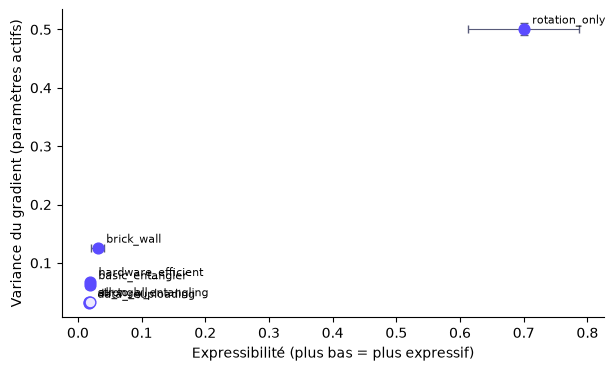

Front de Pareto : ['data_reuploading', 'strongly_entangling', 'basic_entangler', 'hardware_efficient', 'brick_wall', 'rotation_only']


In [3]:
points = list(zip(df["expressibility"], df["gradient_variance_active"]))
on_front = pareto_front(points, minimize_x=True, maximize_y=True)

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(
    df["expressibility"], df["gradient_variance_active"],
    xerr=df["expressibility_std"], yerr=df["gradient_variance_active_std"],
    fmt="none", ecolor="#585B7A", elinewidth=0.8, capsize=3,
)
for (name, row), front in zip(df.iterrows(), on_front):
    ax.scatter(
        row["expressibility"], row["gradient_variance_active"], s=60,
        color="#5B4BFF" if front else "#ECE9FF", edgecolors="#5B4BFF", zorder=2,
    )
    ax.annotate(name, (row["expressibility"], row["gradient_variance_active"]),
                xytext=(6, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("Expressibilité (plus bas = plus expressif)")
ax.set_ylabel("Variance du gradient (paramètres actifs)")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

print("Front de Pareto :", [name for name, front in zip(df.index, on_front) if front])

## Variance du gradient en fonction du nombre de qubits

Mode fixe (3 couches), de 2 à 6 qubits, 100 échantillons, observable locale Z0. Pour chaque ansatz, deux séries :
- paramètres actifs (trait plein) : c'est sur elle que porte la conclusion ;
- tous les paramètres (pointillé) : elle baisse aussi par dilution, quand la part de paramètres inactifs augmente.

L'ajustement exponentiel donne le facteur par lequel la variance est multipliée à chaque qubit ajouté.

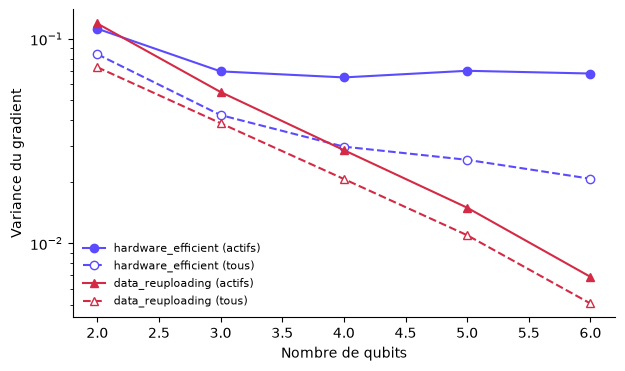

,facteur (actifs),R² (actifs),facteur (tous),R² (tous),part d'inactifs (moyenne)
hardware_efficient,0.904,0.491,0.718,0.908,0.502
data_reuploading,0.496,0.999,0.517,0.998,0.298


In [4]:
studies = {
    name: gradient_scaling(name, range(2, 7), layers=3, layers_mode="fixed", n_samples=100, seed=0)
    for name in ["hardware_efficient", "data_reuploading"]
}

fig, ax = plt.subplots(figsize=(7, 4))
for (name, study), (color, marker) in zip(studies.items(), [("#5B4BFF", "o"), ("#D42A45", "^")]):
    ax.plot(study["n_qubits"], study["active_mean_variance"], color=color, marker=marker,
            label=f"{name} (actifs)")
    ax.plot(study["n_qubits"], study["mean_variance"], color=color, marker=marker,
            linestyle="--", markerfacecolor="white", label=f"{name} (tous)")
ax.set_yscale("log")
ax.set_xlabel("Nombre de qubits")
ax.set_ylabel("Variance du gradient")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8)
plt.show()

fits = pd.DataFrame(
    {
        name: {
            "facteur (actifs)": fit_decay(s["n_qubits"], s["active_mean_variance"])["factor_per_qubit"],
            "R² (actifs)": fit_decay(s["n_qubits"], s["active_mean_variance"])["r2"],
            "facteur (tous)": fit_decay(s["n_qubits"], s["mean_variance"])["factor_per_qubit"],
            "R² (tous)": fit_decay(s["n_qubits"], s["mean_variance"])["r2"],
            "part d'inactifs (moyenne)": s["inactive_fraction"].mean(),
        }
        for name, s in studies.items()
    }
).T
fits.round(3)

## Coût matériel

Transpilation hors ligne (aucune machine contactée) de `data_reuploading` (4 qubits, 3 couches) sur une ligne et sur le réseau heavy-hex de distance 3 (hexagone lourd, 19 qubits). On compare trois niveaux : le circuit d'origine, sa traduction vers les portes `cx, rz, sx, x` et le circuit après routage. Le résultat dépend de la graine du transpileur.

In [5]:
qc = build_ansatz("data_reuploading", 4, 3)
costs = {topology: hardware_cost(qc, topology=topology, seed=0) for topology in ["line", "heavy_hex"]}
pd.DataFrame.from_dict(
    {
        topology: {
            "portes 2q (origine)": c["before"]["n_two_qubit_gates"],
            "portes 2q (traduction)": c["basis_only"]["n_two_qubit_gates"],
            "portes 2q (routage)": c["after"]["n_two_qubit_gates"],
            "profondeur (origine)": c["before"]["depth"],
            "profondeur (routage)": c["after"]["depth"],
            "surcoût du routage": round(c["routing_overhead_two_qubit"], 2),
        }
        for topology, c in costs.items()
    },
    orient="index",
)

,portes 2q (origine),portes 2q (traduction),portes 2q (routage),profondeur (origine),profondeur (routage),surcoût du routage
line,12,12,40,21,56,3.33
heavy_hex,12,12,36,21,54,3.00


## Limites

Ces mesures viennent d'une simulation exacte et sans bruit. La variance du gradient est calculée sur l'observable locale Z0, et ses conclusions dépendent de cette observable et du nombre de couches. Aucun lien n'est démontré ici entre ces métriques et la qualité d'apprentissage d'une QCBM. Voir la section « Limites connues » du README.